# 03 – Embeddings et stockage : PGVector, Qdrant, Chroma DB
**Travail demandé 2** : embeddings open source (`BAAI/bge-m3` pour le texte/tableaux/descriptions, CLIP pour les images) stockés avec leurs métadonnées dans **PGVector**, **Qdrant** et **Chroma**, puis comparaison.

> Prérequis : `docker compose up -d` (PostgreSQL+pgvector sur le port 5433, Qdrant sur 6333).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from src import config
PDF = config.PDF_DIR / "ABB_ACS580_Guide_Variateur.pdf"
print("Projet :", ROOT, "| PDF existe :", PDF.exists())

Projet : c:\Users\OMEN\Downloads\parti 1 projet agent | PDF existe : True


In [2]:
from src.indexer import index_pdf
stats = index_pdf(PDF, backends=['pgvector', 'qdrant', 'chroma'], describe=True)
stats

c:\Users\OMEN\Downloads\parti 1 projet agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[   0%] Analyse du PDF : texte, tableaux, images…
[   2%] Page 1/18 analysée
[   3%] Page 2/18 analysée
[   5%] Page 3/18 analysée
[   7%] Page 4/18 analysée
[   8%] Page 5/18 analysée
[  10%] Page 6/18 analysée
[  12%] Page 7/18 analysée
[  13%] Page 8/18 analysée
[  15%] Page 9/18 analysée
[  17%] Page 10/18 analysée
[  18%] Page 11/18 analysée
[  20%] Page 12/18 analysée
[  22%] Page 13/18 analysée
[  23%] Page 14/18 analysée
[  25%] Page 15/18 analysée
[  27%] Page 16/18 analysée
[  28%] Page 17/18 analysée
[  30%] Page 18/18 analysée
[  30%] Description de l'image 1/8 (page 1) avec qwen3.5:9b
[  35%] Description de l'image 2/8 (page 4) avec qwen3.5:9b
[  40%] Description de l'image 3/8 (page 5) avec qwen3.5:9b
[  45%] Description de l'image 4/8 (page 6) avec qwen3.5:9b
[  50%] Description de l'image 5/8 (page 7) avec qwen3.5:9b
[  55%] Description de l'image 6/8 (page 9) avec qwen3.5:9b
[  60%] Description de l'image 7/8 (page 12) avec qwen3.5:9b
[  65%] Description de l'image 8/8

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 450.44it/s]


[  85%] Stockage dans pgvector…


ConnectionTimeout: connection timeout expired
Multiple connection attempts failed. All failures were:
- host: 'localhost', port: '5433', hostaddr: '::1': connection timeout expired
- host: 'localhost', port: '5433', hostaddr: '127.0.0.1': connection timeout expired

In [ ]:
from src.embeddings import get_text_embedder, get_clip_embedder
from src.vectorstore import open_store
te, ce = get_text_embedder(), get_clip_embedder()
stores = {n: open_store(n, te.dim, ce.dim) for n in config.BACKENDS}
{n: s.count() for n, s in stores.items()}

{'pgvector': 60, 'qdrant': 60, 'chroma': 60}

## Exemple de recherche dans chaque base

In [ ]:
q = 'Comment corriger une surintensité au démarrage ?'
qv = te.embed_query(q)
for n, s in stores.items():
    print(f'===== {n}')
    for h in s.search(qv, 'text', None, 3):
        print(f"  {h.score:.3f} | p{h.element['page']} | {h.element['type']} | {h.element['content'][:90]!r}")

===== pgvector
  0.633 | p13 | table | 'Tableau extrait de la page 13\n\n| Code | Nom (panneau) | Cause probable | Action corrective'
  0.586 | p17 | text | "R : Lors d'une décélération rapide d'une charge à forte inertie, le moteur fonctionne en\ng"
  0.552 | p12 | table | 'Tableau extrait de la page 12\n\n| Code | Nom (panneau) | Cause probable | Action corrective'
===== qdrant
  0.633 | p13 | table | 'Tableau extrait de la page 13\n\n| Code | Nom (panneau) | Cause probable | Action corrective'
  0.586 | p17 | text | "R : Lors d'une décélération rapide d'une charge à forte inertie, le moteur fonctionne en\ng"
  0.552 | p12 | table | 'Tableau extrait de la page 12\n\n| Code | Nom (panneau) | Cause probable | Action corrective'
===== chroma
  0.633 | p13 | table | 'Tableau extrait de la page 13\n\n| Code | Nom (panneau) | Cause probable | Action corrective'
  0.586 | p17 | text | "R : Lors d'une décélération rapide d'une charge à forte inertie, le moteur fonctionne en\ng"
  0.552 | p12

## Benchmark : latence et précision (hit@5)
Une réponse est « trouvée » si le mot-clé attendu apparaît dans l'un des 5 premiers résultats (texte + tableaux).

In [ ]:
import time, pandas as pd, numpy as np
TESTS = [
  ('Que signifie le défaut 2310 ?', '2310'),
  ('Quel défaut indique une fuite à la terre du moteur ?', '2330'),
  ('Tous les combien remplacer le ventilateur principal R0-R5 ?', '3 ans'),
  ('Quelle sortie relais signale un défaut avec la macro ABB standard ?', 'RO3'),
  ('Que faire si le variateur est resté stocké plus d un an ?', 'reform'),
  ('Quel niveau de sécurité atteint la fonction STO ?', 'SIL 3'),
  ('Quel paramètre règle le temps d accélération ?', '23.12'),
  ('Pourquoi un variateur économise de l énergie sur une pompe ?', 'n³'),
  ('Comment nettoyer le radiateur du variateur ?', 'air comprimé'),
  ('Le variateur déclenche en surtension du bus continu lors des arrêts', '3210'),
]
rows = []
for n, s in stores.items():
    lat, hits = [], 0
    for q, kw in TESTS:
        qv = te.embed_query(q)
        t0 = time.perf_counter()
        res = s.search(qv, 'text', 'text', 5) + s.search(qv, 'text', 'table', 5)
        lat.append((time.perf_counter() - t0) * 1000)
        res = sorted(res, key=lambda h: -h.score)[:5]
        hits += any(kw.lower() in h.element['content'].lower() for h in res)
    rows.append({'base': n, 'latence moyenne (ms)': np.mean(lat), 'latence p95 (ms)': np.percentile(lat, 95),
                 'hit@5': hits / len(TESTS)})
bench = pd.DataFrame(rows).set_index('base').round(3)
bench

,latence moyenne (ms),latence p95 (ms),hit@5
base,,,
pgvector,90.518,92.368,1.0
qdrant,82.112,121.993,1.0
chroma,9.481,11.253,1.0


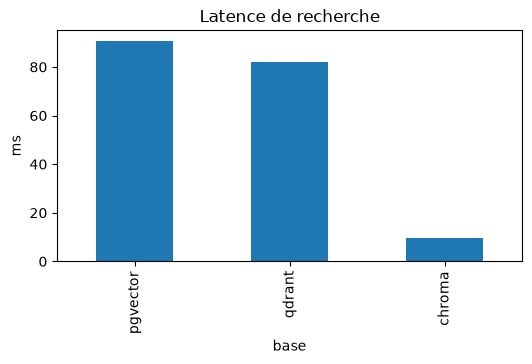

In [ ]:
ax = bench[['latence moyenne (ms)']].plot.bar(figsize=(6, 3), legend=False, title='Latence de recherche')
ax.set_ylabel('ms');